# Actividad 2. Dataset - Notebook
#Nombre: Sauza Machado Eduardo Daniel
#Matrícula: A01797466

Inicio. Se carga el entorno

Se selecciona la Base "Bank Marketing" desde Kaggle

In [ ]:
!pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("henriqueyamahata/bank-marketing")
print(path)

Using Colab cache for faster access to the 'bank-marketing' dataset.
/kaggle/input/bank-marketing


In [ ]:
import os

os.listdir(path)

['bank-additional-names.txt', 'bank-additional-full.csv']

**Paso 1.- Carga y descripción el dataset**

In [ ]:
import pandas as pd
archivo = path + "/bank-additional-full.csv"
DF=pd.read_csv(archivo, sep=";")
DF.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
#Documentación oficial de la base
with open(path + "/bank-additional-names.txt", "r") as archivo:
    descripcion = archivo.read()

print(descripcion)

﻿Citation Request:
  This dataset is publicly available for research. The details are described in [Moro et al., 2014]. 
  Please include this citation if you plan to use this database:

  [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, In press, http://dx.doi.org/10.1016/j.dss.2014.03.001

  Available at: [pdf] http://dx.doi.org/10.1016/j.dss.2014.03.001
                [bib] http://www3.dsi.uminho.pt/pcortez/bib/2014-dss.txt

1. Title: Bank Marketing (with social/economic context)

2. Sources
   Created by: Sérgio Moro (ISCTE-IUL), Paulo Cortez (Univ. Minho) and Paulo Rita (ISCTE-IUL) @ 2014
   
3. Past Usage:

  The full dataset (bank-additional-full.csv) was described and analyzed in:

  S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems (2014), doi:10.1016/j.dss.2014.03.001.
 
4. Relevant Information:

   This

In [ ]:
#Tamaño de la base
DF.shape

(41188, 21)

In [ ]:
#Información de la base
DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

El dataset contiene 41,188 registros y 21 variables, de las cuales 20 corresponden a variables predictoras y y representa la variable objetivo.  
Se identificó:
*   10 variables numéricas: 5 de tipo entero (int64)
*   5 de tipo decimal (float64)
*   11 variables categóricas almacenadas como object, incluyendo la variable objetivo
*   De acuerdo con df.info(), ninguna columna contiene valores nulos (NaN). Sin embargo, la documentación del dataset indica que algunas variables categóricas representan valores faltantes mediante la categoría unknown, por lo que estos casos deberán analizarse posteriormente durante la etapa de limpieza.

*   El problema corresponde a una clasificación binaria, donde la variable y indica si el cliente contrató (yes) o no (no) un depósito bancario a plazo.

Por otro lado, se muestra el resumen del significado de las variables:
| Variable | Tipo | Significado |
|---|---|---|
| `age` | Numérica | Edad del cliente. |
| `job` | Categórica | Tipo de ocupación del cliente. |
| `marital` | Categórica | Estado civil del cliente. |
| `education` | Categórica | Nivel educativo del cliente. |
| `default` | Categórica | Indica si el cliente tiene un crédito en incumplimiento. |
| `housing` | Categórica | Indica si tiene un crédito hipotecario. |
| `loan` | Categórica | Indica si tiene un préstamo personal. |
| `contact` | Categórica | Medio utilizado para contactar al cliente: celular o teléfono. |
| `month` | Categórica | Mes en que se realizó el último contacto. |
| `day_of_week` | Categórica | Día de la semana del último contacto. |
| `duration` | Numérica | Duración del último contacto, medida en segundos. |
| `campaign` | Numérica | Número de contactos realizados al cliente durante la campaña actual, incluyendo el último. |
| `pdays` | Numérica | Días transcurridos desde que el cliente fue contactado en una campaña anterior. El valor `999` indica que no había sido contactado previamente. |
| `previous` | Numérica | Número de contactos realizados al cliente antes de la campaña actual. |
| `poutcome` | Categórica | Resultado de la campaña de marketing anterior: éxito, fracaso o inexistente. |
| `emp.var.rate` | Numérica | Tasa de variación del empleo; indicador trimestral. |
| `cons.price.idx` | Numérica | Índice de precios al consumidor; indicador mensual. |
| `cons.conf.idx` | Numérica | Índice de confianza del consumidor; indicador mensual. |
| `euribor3m` | Numérica | Tasa Euribor a tres meses; indicador diario. |
| `nr.employed` | Numérica | Número de empleados; indicador trimestral. |
| **`y`** | **Categórica/binaria** | **Variable objetivo. Indica si el cliente contrató un depósito a plazo (`yes`/`no`).** |






**Paso 2: Análisis exploratorio (EDA)**

2.- Estadísticas descriptivas

In [ ]:
#Primero revisemos las variables numéricas
DF.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


Las variables numéricas presentan distintos comportamientos:

*   La edad promedio de los clientes es de aproximadamente 40 años, con la mayor parte de las observaciones entre 32 y 47 años, aunque existen clientes de hasta 98 años.
*   La duración de las llamadas (duration) presenta una alta dispersión: la mediana es de 180 segundos, mientras que el máximo alcanza 4,918 segundos, lo que sugiere una distribución asimétrica y posibles valores extremos. De manera similar, campaign tiene una mediana de 2 contactos, pero alcanza un máximo de 56.
*   En pdays, los percentiles 25%, 50% y 75% tienen un valor de 999. De acuerdo con la documentación del dataset, este valor indica que el cliente no había sido contactado previamente, por lo que no debe interpretarse como 999 días reales. Esto coincide con previous, cuya mediana es 0, indicando que gran parte de los clientes no tuvo contactos anteriores.
*   Las variables emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m y nr.employed representan el contexto socioeconómico y presentan diferentes niveles de variabilidad durante el periodo analizado.

In [23]:
#Segundo, revisemos las variables categóricas
DF.describe(include="object").T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


Resumen de variables categóricas:

*   Las variables categóricas presentan diferentes niveles de concentración
*   Predominan los clientes casados, con empleos administrativos y estudios universitarios
*   La mayoría de los contactos se realizaron por celular y mayo fue el mes con mayor número de registros
*   La variable poutcome muestra principalmente la categoría nonexistent, lo que indica que gran parte de los clientes no contaba con un resultado de campañas anteriores
*   La variable objetivo *y* presenta un desbalance importante, ya que la mayoría de los clientes no contrató el depósito a plazo

Un hallazgo particularmente relevante es el desbalance de la variable objetivo y: 36,548 observaciones corresponden a clientes que no contrataron el depósito, frente a 4,640 que sí lo hicieron. Por ello, durante la evaluación del modelo será necesario considerar métricas adicionales a la exactitud (accuracy).



  

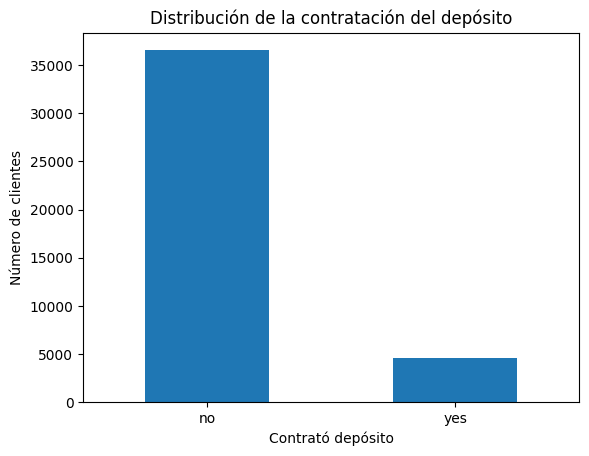

In [24]:
#Tercero: Visualizaciones
import matplotlib.pyplot as plt
DF["y"].value_counts().plot(kind="bar")
plt.title("Distribución de la contratación del depósito")
plt.xlabel("Contrató depósito")
plt.ylabel("Número de clientes")
plt.xticks(rotation=0)
plt.show()

Análisis: Se observa un marcado desbalance en la variable objetivo. La mayoría de los clientes (36,548; 88.7%) no contrató el depósito a plazo, mientras que únicamente 4,640 (11.3%) sí lo hizo. Esta diferencia será relevante durante la evaluación del modelo, ya que una exactitud (accuracy) elevada podría no representar adecuadamente su capacidad para identificar a los clientes que sí contratan. Por ello, posteriormente se considerarán métricas complementarias como precision, recall y F1.

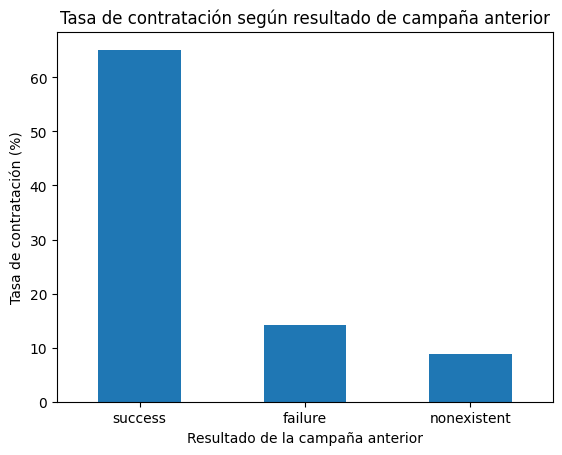

In [25]:
tasa_poutcome = (
    DF.assign(y_num=(DF["y"] == "yes").astype(int))
      .groupby("poutcome")["y_num"]
      .mean()
      .mul(100)
      .sort_values(ascending=False))
tasa_poutcome.plot(kind="bar")
plt.title("Tasa de contratación según resultado de campaña anterior")
plt.xlabel("Resultado de la campaña anterior")
plt.ylabel("Tasa de contratación (%)")
plt.xticks(rotation=0)
plt.show()

Análisis: Se observa una relación importante entre el resultado de la campaña anterior y la contratación del depósito. Los clientes cuya campaña previa fue exitosa presentan una tasa de contratación cercana al 65%, considerablemente superior a quienes tuvieron una campaña previa fallida (aprox. 14%) o no registran una campaña anterior (aprox. 9%). Esto sugiere que poutcome podría ser una variable relevante para predecir la respuesta del cliente

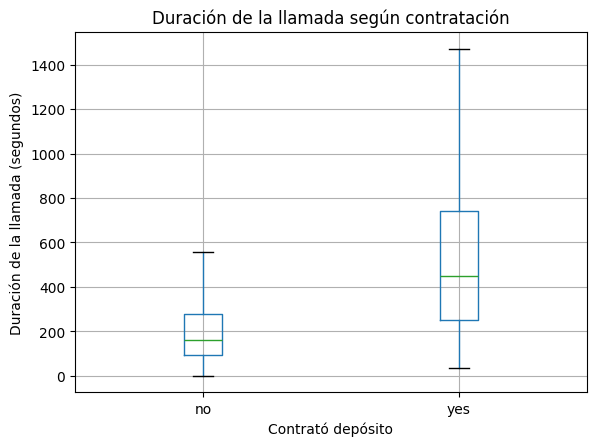

In [26]:
DF.boxplot(column="duration", by="y", showfliers=False)
plt.title("Duración de la llamada según contratación")
plt.suptitle("")
plt.xlabel("Contrató depósito")
plt.ylabel("Duración de la llamada (segundos)")
plt.show()

Análisis: Los clientes que contrataron el depósito presentan llamadas considerablemente más largas que aquellos que no lo contrataron. La mediana de duración es claramente superior para la clase yes, lo que indica una fuerte relación entre duration y la variable objetivo. Sin embargo, esta variable no se utilizará para entrenar el modelo baseline, ya que su valor solo se conoce una vez realizada la llamada. Incluirla produciría un modelo poco realista para realizar predicciones antes del contacto.

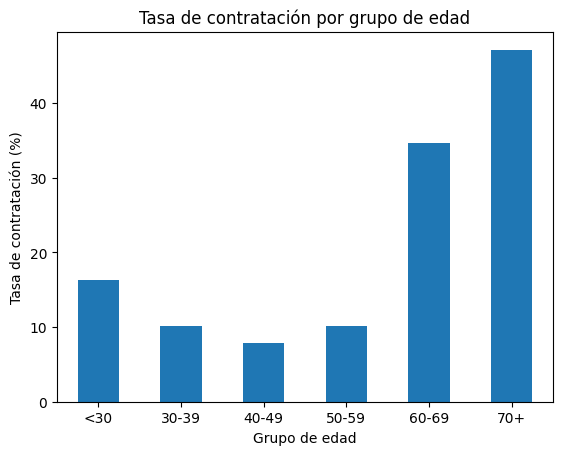

In [27]:
rangos = [0, 29, 39, 49, 59, 69, 100]
etiquetas = ["<30", "30-39", "40-49", "50-59", "60-69", "70+"]
edad_grupo = pd.cut(
    DF["age"],
    bins=rangos,
    labels=etiquetas)
tasa_edad = (
    DF.assign(
        grupo_edad=edad_grupo,
        y_num=(DF["y"] == "yes").astype(int)
    )
    .groupby("grupo_edad", observed=True)["y_num"]
    .mean()
    .mul(100))
tasa_edad.plot(kind="bar")
plt.title("Tasa de contratación por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Tasa de contratación (%)")
plt.xticks(rotation=0)
plt.show()

Análisis: La tasa de contratación presenta diferencias importantes entre los grupos de edad. Los clientes entre 40 y 49 años muestran la menor proporción de contratación, mientras que esta aumenta considerablemente a partir de los 60 años, alcanzando su mayor nivel entre los clientes de 70 años o más. También se observa una tasa relativamente mayor entre los menores de 30 años. Estos resultados sugieren que la edad puede aportar información relevante para la predicción de la contratación.

**Paso 3: Limpieza de datos**

3.1.- Valores faltantes


No aportaría mucha información usar el comando "DF.isnull().sum()" debido a que anteriormente ya habíamos observado que no había valores NULL. Sin embargo, la documentación indica que algunos faltantes están codificados como unknown. Por lo que hay que revisar dicho tema.

In [29]:
unknown = (DF == "unknown").sum()
unknown[unknown > 0].sort_values(ascending=False)

,0
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


Se enlistan el porcentaje de valores faltantes de cada columna:

*   default: 8,597 (~20.9%)
*   education: 1,731 (~4.2%)
*   housing: 990 (~2.4%)
*   loan: 990 (~2.4%)
*   job: 330 (~0.8%)
*   marital: 80 (~0.2%)

Para el modelo baseline se decidió conservar *unknown* como una categoría independiente, evitndo eliminar observaciones o imputar valores sin evidencia suficiente. Debido a que se podría peder un 20% de la información, lo que es demasiado.

3.2.- Duplicados

In [30]:
DF.duplicated().sum()

np.int64(12)

In [32]:
DF[DF.duplicated(keep=False)].sort_values(
    by=list(DF.columns))

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


Consideré eliminar las filas duplicadas para nuestro baseline. Aunque no existe un identificador de cliente que permita demostrar que corresponden al mismo individuo, son registros idénticos en las 21 variables y representan una proporción mínima del conjunto. Sin embargo, su eliminación evita que observaciones exactamente repetidas influyan innecesariamente en el entrenamiento.

In [33]:
#Eliminación de los duplicados
DF = DF.drop_duplicates().reset_index(drop=True)
DF.shape

(41176, 21)

Resumen: Se identificaron 12 registros duplicados, equivalentes aproximadamente al 0.03% del dataset. Debido a que presentan valores idénticos en todas las variables y representan una proporción mínima de los datos, se decidió eliminarlos para evitar redundancia durante el entrenamiento. Después de la limpieza, el dataset quedó conformado por 41,176 registros

3.3.- Valores aislados

Se utilizó el método del rango intercuartílico (IQR) porque permite identificar valores extremos a partir de la distribución de los datos sin asumir que siguen una distribución normal. Se consideran potenciales outliers aquellos valores inferiores a \(Q1 - 1.5 \times IQR\) o superiores a \(Q3 + 1.5 \times IQR\). Los valores detectados serán analizados antes de decidir su eliminación, ya que un valor estadísticamente atípico no necesariamente representa un dato incorrecto.

In [35]:
columnas_numericas = DF.select_dtypes(include=["int64", "float64"]).columns
for columna in columnas_numericas:
    Q1 = DF[columna].quantile(0.25)
    Q3 = DF[columna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    outliers = DF[
        (DF[columna] < limite_inferior) |
        (DF[columna] > limite_superior)]
    print(f"{columna}: {len(outliers)} outliers")

age: 468 outliers
duration: 2963 outliers
campaign: 2406 outliers
pdays: 1515 outliers
previous: 5625 outliers
emp.var.rate: 0 outliers
cons.price.idx: 0 outliers
cons.conf.idx: 446 outliers
euribor3m: 0 outliers
nr.employed: 0 outliers


In [36]:
#Muestras de mínimos y máximos
numericas = DF.select_dtypes(include=["int64", "float64"])
rangos = numericas.agg(["min", "max"]).T
rangos.columns = ["Mínimo", "Máximo"]
rangos

,Mínimo,Máximo
age,17.000,98.000
duration,0.000,4918.000
campaign,1.000,56.000
pdays,0.000,999.000
previous,0.000,7.000
emp.var.rate,-3.400,1.400
cons.price.idx,92.201,94.767
cons.conf.idx,-50.800,-26.900
euribor3m,0.634,5.045
nr.employed,4963.600,5228.100


El análisis de los rangos no muestra valores evidentemente inválidos o imposibles. age se encuentra entre 17 y 98 años, por lo que incluso las edades detectadas como outliers mediante IQR son plausibles. duration, campaign y previous presentan máximos elevados respecto a su distribución, pero siguen siendo valores posibles y no hay valores negativos. En pdays, el máximo de 999 corresponde a una codificación definida por el propio dataset para clientes que no habían sido contactados previamente, por lo que no representa un error. Las variables socioeconómicas también presentan rangos consistentes, sin valores extremos que sugieran errores de captura. Por lo tanto, no se eliminarán registros adicionales por valores atípicos, ya que los casos detectados por IQR parecen corresponder a observaciones válidas y no a problemas de calidad de datos.

3.4.- Revisión de tipo de datos

In [37]:
DF.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


Revisión de tipos de datos: Se verificaron los tipos de las 21 variables. Las variables discretas como age, duration, campaign, pdays y previous están almacenadas como enteros (int64), mientras que las variables socioeconómicas se encuentran correctamente representadas como valores decimales (float64). Las variables cualitativas y la variable objetivo y están almacenadas como object, lo cual es consistente con su contenido categórico. Por lo tanto, no se identificaron tipos de datos incorrectos que requieran corrección. Las variables categóricas serán codificadas posteriormente durante la preparación de los datos para el modelo

**Paso 4: Entrenamiento de un modelo base**

Se seleccionó una Regresión Logística como modelo baseline debido a que el problema corresponde a una clasificación binaria y se busca establecer un punto de referencia sencillo e interpretable.

Por otro lado, la variable duration fue excluida de los predictores debido a que representa la duración de la llamada y solo se conoce una vez realizada, por lo que utilizarla introduciría información que no estaría disponible al momento de realizar una predicción real.

4.1 Separar predictores y variable objetivo

In [38]:
# Variable objetivo
y = DF["y"]
# Variables predictoras
# Se excluye 'y' por ser el objetivo y 'duration' para evitar fuga de información
X = DF.drop(columns=["y", "duration"])
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (41176, 19)
Dimensiones de y: (41176,)


4.2 División entrenamiento/prueba


Ahora dividimos los datos en 80% entrenamiento y 20% prueba. Como y está desbalanceada, utilizaremos stratify=y para mantener aproximadamente la misma proporción de yes y no en ambos conjuntos.

Configuración del experimento:

*   test_size=0.20: reservamos 20% para evaluar el modelo con datos que no utilizó para entrenarse.
*   random_state=42: hace que la división sea reproducible, algo especialmente relevante en esta materia de MLOps.
*   stratify=y: conserva el desbalance original (~89% no, ~11% yes) tanto en entrenamiento como en prueba.

In [39]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y)
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nDistribución entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nDistribución prueba:")
print(y_test.value_counts(normalize=True))

Entrenamiento: (32940, 19)
Prueba: (8236, 19)

Distribución entrenamiento:
y
no     0.887341
yes    0.112659
Name: proportion, dtype: float64

Distribución prueba:
y
no     0.887324
yes    0.112676
Name: proportion, dtype: float64


División de los datos: El dataset se dividió en 80% para entrenamiento (32,940 registros) y 20% para prueba (8,236 registros). Se utilizó una partición estratificada para conservar la distribución de la variable objetivo en ambos conjuntos. Como resultado, tanto entrenamiento como prueba mantienen aproximadamente 88.7% de casos no y 11.3% de casos yes. Además, se estableció random_state=42 para garantizar la reproducibilidad del experimento.

4.3.- Prepocesamiento

Ahora necesitamos convertir las variables object en números para que la Regresión Logística pueda procesarlas. Utilizaremos One-Hot Encoding para las categóricas y StandardScaler para las numéricas.
Lo más limpio es hacerlo mediante ColumnTransformer, porque posteriormente podemos integrarlo con el modelo en un Pipeline.

In [40]:
# Identificar variables categóricas y numéricas
columnas_categoricas = X_train.select_dtypes(include=["object"]).columns
columnas_numericas = X_train.select_dtypes(include=["int64", "float64"]).columns

print("Variables categóricas:", len(columnas_categoricas))
print(list(columnas_categoricas))

print("\nVariables numéricas:", len(columnas_numericas))
print(list(columnas_numericas))

Variables categóricas: 10
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Variables numéricas: 9
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


4.4.- Construir el pipeline

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
# Preprocesamiento de variables
preprocesador = ColumnTransformer(
    transformers=[
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas),
        ("numericas", StandardScaler(), columnas_numericas)])
# Pipeline: preprocesamiento + modelo
modelo = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("clasificador", LogisticRegression(max_iter=1000))])
# Entrenamiento del modelo
modelo.fit(X_train, y_train)
print("Modelo entrenado correctamente")

Modelo entrenado correctamente


Preprocesamiento y entrenamiento: Las variables categóricas fueron transformadas mediante One-Hot Encoding y las variables numéricas fueron estandarizadas mediante StandardScaler. Ambas transformaciones se integraron junto con una Regresión Logística mediante un Pipeline de Scikit-learn. Esto permite aplicar consistentemente el mismo preprocesamiento durante entrenamiento y predicción, además de evitar que información del conjunto de prueba intervenga en el ajuste de las transformaciones. Se utilizó Regresión Logística como modelo baseline por tratarse de un problema de clasificación binaria y por proporcionar un punto de referencia sencillo e interpretable.

**Paso 5: Evaluación del modelo**

5.1.- Obtención de las predicciones y las métricas:

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report)
# Predicciones sobre el conjunto de prueba
y_pred = modelo.predict(X_test)
# Probabilidad de la clase positiva "yes"
y_prob = modelo.predict_proba(X_test)[:, 1]
# Métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="yes")
recall = recall_score(y_test, y_pred, pos_label="yes")
f1 = f1_score(y_test, y_pred, pos_label="yes")
roc_auc = roc_auc_score((y_test == "yes").astype(int), y_prob)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred, labels=["no", "yes"]))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

Accuracy:  0.8983
Precision: 0.6500
Recall:    0.2101
F1-score:  0.3176
ROC-AUC:   0.8004

Matriz de confusión:
[[7203  105]
 [ 733  195]]

Reporte de clasificación:
              precision    recall  f1-score   support

          no       0.91      0.99      0.95      7308
         yes       0.65      0.21      0.32       928

    accuracy                           0.90      8236
   macro avg       0.78      0.60      0.63      8236
weighted avg       0.88      0.90      0.87      8236



Interpretación de las métricas:

- Accuracy (0.8983): El modelo clasifica correctamente el 89.83% de los registros. Sin embargo, esta métrica debe interpretarse con cautela debido al fuerte desbalance de clases, ya que aproximadamente el 89% de los clientes pertenece a la clase no.

- Precision (0.6500): De los clientes que el modelo predice que sí contratarán el depósito, el 65.0% realmente lo hace. Esto indica una precisión razonable cuando el modelo decide clasificar a un cliente como yes.

- Recall (0.2101): El modelo identifica solamente al 21.01% de todos los clientes que realmente contrataron. Es la principal debilidad del baseline: deja sin identificar aproximadamente al 79% de los clientes positivos (733 de 928).

- F1-score (0.3176): El valor de 31.76% refleja el bajo equilibrio entre precision y recall. Aunque la precision es relativamente buena, el recall reducido penaliza considerablemente esta métrica.

- ROC-AUC (0.8004): Un valor de 0.8004 indica que el modelo posee una buena capacidad de discriminación entre clientes que contratan y no contratan a través de diferentes umbrales de clasificación. Esto sugiere que el modelo tiene información predictiva útil, aunque el umbral actual produce un recall bajo.

- Matriz de confusión: El modelo clasificó correctamente 7,203 clientes como no y 195 como yes. Cometió 105 falsos positivos y 733 falsos negativos. Esto confirma que el modelo baseline favorece fuertemente la identificación de la clase mayoritaria y tiene dificultades para detectar clientes que realmente contratarán.

Conclusión: el baseline tiene un accuracy alto y un ROC-AUC razonablemente bueno, pero el recall de la clase yes es bajo. Por ello, el 89.83% de accuracy por sí solo daría una impresión demasiado optimista del desempeño del modelo.

**Paso 6: Registro del experimento en MLFlow**

In [44]:
#Instlación del entorno mlflow
!pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 79.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 85.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [45]:
import mlflow
print("Versión de MLflow:", mlflow.__version__)

Versión de MLflow: 3.16.1


6.1.- Crear el experimento y registrar parámetros y métricas

In [46]:
# Nombre del experimento
mlflow.set_experiment("Bank_Marketing_Baseline")

with mlflow.start_run(run_name="LogisticRegression_Baseline"):

    # Parámetros del experimento
    mlflow.log_param("modelo", "LogisticRegression")
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("stratify", True)
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("duration_excluida", True)

    # Métricas obtenidas anteriormente
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)
    mlflow.log_metric("roc_auc", roc_auc)

    print("Experimento registrado correctamente en MLflow.")

2026/10/04 19:55:27 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/04 19:55:28 INFO mlflow.store.db.utils: Updating database tables
2026/10/04 19:55:31 INFO mlflow.tracking.fluent: Experiment with name 'Bank_Marketing_Baseline' does not exist. Creating a new experiment.


Experimento registrado correctamente en MLflow.


Se utilizó MLflow Tracking para registrar de manera reproducible la configuración y los resultados del modelo baseline. Se almacenaron los principales parámetros utilizados durante el experimento y las métricas obtenidas sobre el conjunto de prueba. Esto permite mantener trazabilidad sobre las condiciones bajo las cuales se obtuvo cada resultado y facilita la comparación con futuros experimentos.

### Evidencia del registro en MLflow

A continuación se presenta la evidencia del experimento `Bank_Marketing_Baseline` registrado en MLflow. Se muestra el run `LogisticRegression_Baseline`, así como las métricas y parámetros almacenados durante la ejecución.

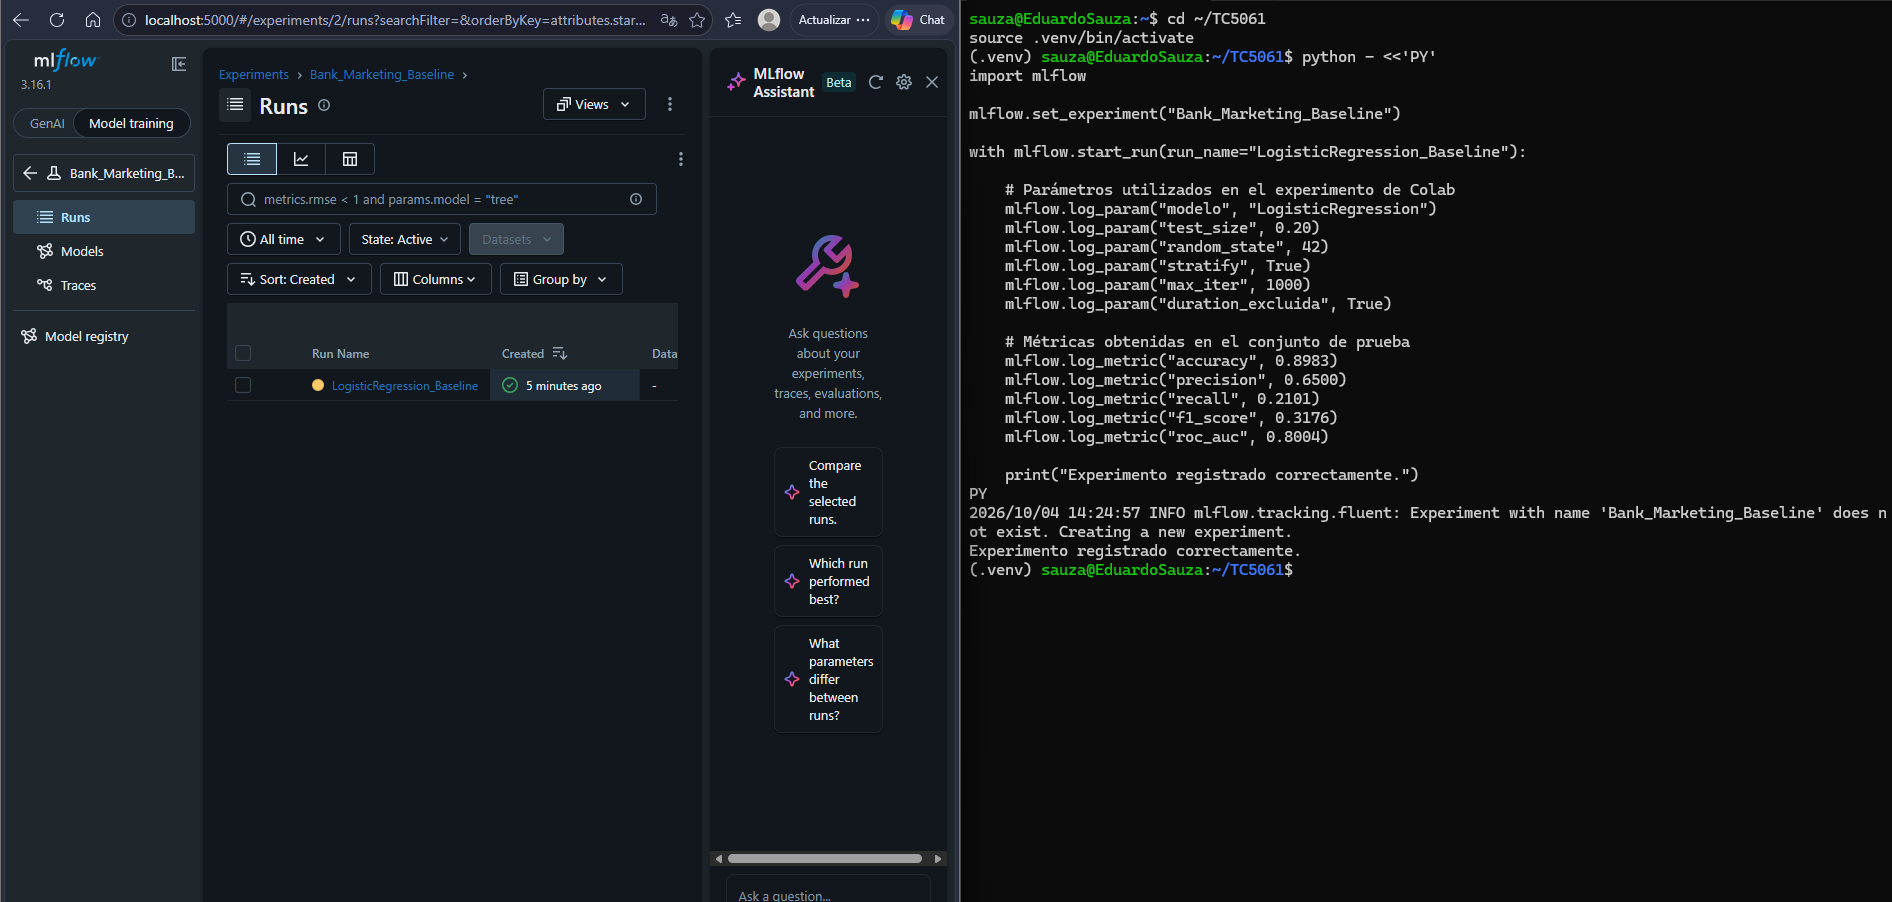

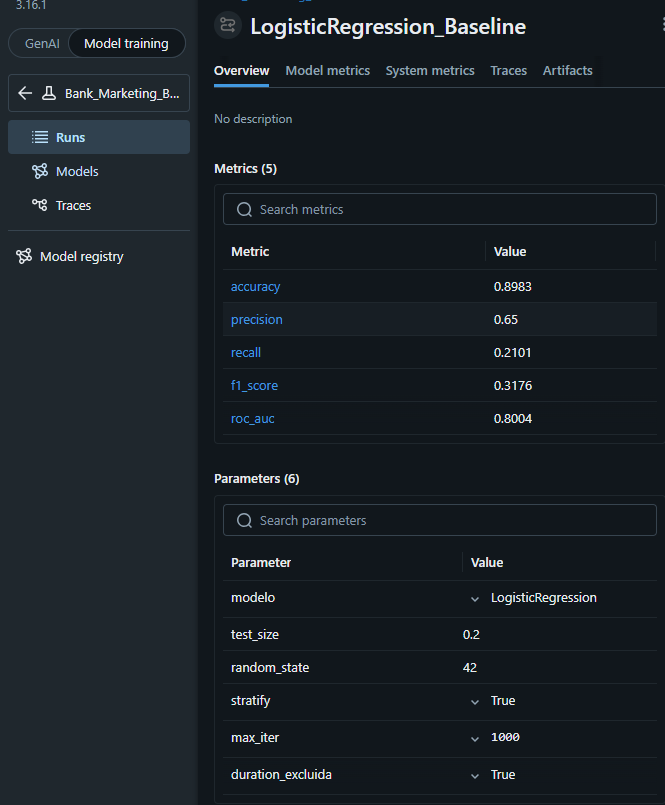

**Paso 7: Reflexión sobre MLOps**

El desarrollo de este modelo baseline me permitió recorrer las principales etapas de un proyecto de aprendizaje automático, desde el análisis y limpieza de los datos hasta el entrenamiento, evaluación y registro del experimento.

Un aspecto que ha sido constante a lo largo de las materias relacionadas con aprendizaje automático es el análisis exploratorio de datos (EDA). Su presencia constante demuestra que comprender los datos es una etapa imprescindible antes de construir cualquier modelo. Realizar análisis estadísticos, estudiar distribuciones, identificar valores atípicos y analizar las relaciones entre variables permite detectar problemas y tomar decisiones fundamentadas sobre la preparación de los datos. Este ejercicio reforzó la idea de que un buen modelo no comienza con el algoritmo, sino con una comprensión adecuada de la información disponible.

Por otro lado, el flujo realizado se hizo reproducible (se fijó una semilla) a nivel de notebook. Sin embargo, en un entorno productivo sería necesario incorporar otras prácticas de MLOps que permitan automatizar y controlar cada una de estas etapas:

*   Versionamiento: versionar conjuntamente el código, los datos y los modelos para poder identificar exactamente qué elementos generaron cada resultado.

*   Seguimiento de experimentos: utilizar MLflow para registrar parámetros, métricas y resultados, facilitando la trazabilidad y comparación entre diferentes experimentos.

*   Automatización del pipeline: transformar las etapas de preparación de datos, entrenamiento y evaluación en un flujo automatizado y reproducible, reduciendo procesos manuales.

*   Validación y pruebas: incorporar controles automáticos de calidad de los datos y pruebas del código antes de ejecutar nuevos entrenamientos o desplegar modelos.

*   Monitoreo: una vez desplegado el modelo, supervisar su desempeño y detectar cambios en la distribución de los datos (data drift) o posibles degradaciones en su capacidad predictiva.

En mi trabajo, una de las prácticas de MLOps que considero más aplicables es el seguimiento de experimentos mediante herramientas como MLflow. En proyectos de datos y aprendizaje automático es común realizar múltiples pruebas modificando variables, parámetros, algoritmos o criterios de preparación de los datos. Sin un registro estructurado, puede resultar difícil determinar posteriormente qué configuración produjo un resultado específico. MLflow permite mantener esta trazabilidad al relacionar cada ejecución con sus parámetros, métricas y artefactos, facilitando la comparación de experimentos y la reproducción de resultados.

Finalmente, una plataforma de seguimiento permite mantener un historial del ciclo de vida del modelo. Si posteriormente se detecta una incidencia, es posible consultar experimentos anteriores, comparar resultados y determinar qué cambió entre versiones. En mi ámbito profesional, donde gran parte del trabajo está relacionado con datos, automatización y la evolución de iniciativas de IA hacia soluciones productivas, esta capacidad de trazabilidad puede reducir procesos manuales, facilitar auditorías técnicas y brinda de mayor control un proyecto donde participe un equipo.